# Static Markov attribution on GA4 ecommerce journeys

Order-1 absorbing-Markov-chain attribution on
`ga4_attribution_journeys.csv` — a journey-level extract of Google's public
obfuscated GA4 ecommerce sample (Google Merchandise Store, Nov 2020 - Jan
2021): one row per journey with an ordered channel path, a binary
conversion flag, and an anchor timestamp.

Attribution shares are probabilistic decompositions of observed
co-occurrence between channel exposure and purchase — descriptive, not
causal.

In [1]:
# In Colab, install the package first:
# %pip install "do-attribution[viz,temporal]"
%matplotlib inline
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore", message="Sum of Shapley values")
warnings.filterwarnings("ignore", message="Total removal effect is 0")
pd.set_option("display.width", 160)

IMAGES = Path("images")
IMAGES.mkdir(exist_ok=True)

## Load and summarize the GA4 journeys

In [2]:
journeys = pd.read_csv("ga4_attribution_journeys.csv")

required = {"path", "conversion", "anchor_timestamp"}
assert required.issubset(journeys.columns), f"missing columns: {required - set(journeys.columns)}"
assert journeys["path"].notna().all() and (journeys["path"].str.len() > 0).all()
assert journeys["conversion"].isin([0, 1]).all()

paths = journeys["path"]
conversions = journeys["conversion"]
timestamps = pd.to_datetime(journeys["anchor_timestamp"]).dt.tz_localize(None)

channels = sorted({channel for path in paths for channel in path.split(" > ")})
path_lengths = paths.str.count(" > ") + 1
print(f"journeys        : {len(journeys):,}")
print(f"conversions     : {conversions.sum():,}  (rate {conversions.mean():.4f})")
print(f"date range      : {timestamps.min().date()} to {timestamps.max().date()}")
print(f"channels ({len(channels)})    : {', '.join(channels)}")
print(f"path length     : mean {path_lengths.mean():.2f}, max {path_lengths.max()}; "
      f"{(path_lengths > 1).mean():.1%} of journeys are multi-touch")
journeys.head()

journeys        : 272,792
conversions     : 4,848  (rate 0.0178)
date range      : 2020-11-01 to 2021-01-31
channels (8)    : Affiliate, Direct, Email, Organic Search, Organic Social, Other, Paid Search, Referral
path length     : mean 1.17, max 12; 11.4% of journeys are multi-touch


,journey_id,path,conversion,journey_start,anchor_timestamp,session_count,touch_count,purchase_count
0,journey_0000001,Organic Search,0,2020-12-12T04:11:17Z,2020-12-12T04:11:17Z,1,1,0
1,journey_0000002,Direct,0,2021-01-07T18:35:34Z,2021-01-07T18:35:34Z,1,1,0
2,journey_0000003,Direct,0,2021-01-20T11:04:59Z,2021-01-20T11:04:59Z,1,1,0
3,journey_0000004,Other > Referral,0,2020-11-04T09:21:11Z,2020-11-04T13:43:30Z,2,2,0
4,journey_0000005,Organic Search,0,2020-12-11T17:25:12Z,2020-12-11T17:25:12Z,1,1,0


## Fit an order-1 Markov model

`removal_strategy="redirect_to_null"` is the classic removal-effect
definition: the removed channel's transition mass is redirected to `NULL`
on the fitted matrix and the absorption probability is recomputed in
closed form from the fundamental matrix — deterministic, no simulation.
(`"fail"` and `"detour"` provide alternative removal definitions.)

In [3]:
from do_attribution import MarkovAttribution

markov = MarkovAttribution(
    order=1,
    removal_strategy="redirect_to_null",
    return_transition_matrix=True,
)
markov_result = markov.fit(paths, conversions)
print(f"P(conversion | start) = {markov_result['total_conversion_probability']:.4f} "
      f"(observed rate {conversions.mean():.4f})")

P(conversion | start) = 0.0178 (observed rate 0.0178)


## Attribution shares and removal effects

In [4]:
shares = pd.Series(markov_result["attribution"], name="share").sort_values(ascending=False)
effects = pd.Series(markov_result["removal_effects"], name="removal_effect")
display(pd.DataFrame({"share": shares.round(4), "removal_effect": effects.reindex(shares.index).round(4)}))
print(f"shares sum to {shares.sum():.6f}")

,share,removal_effect
Referral,0.4290,0.5276
Organic Search,0.3621,0.4453
Direct,0.1077,0.1324
Other,0.0801,0.0985
Paid Search,0.0140,0.0172
Email,0.0040,0.0050
Affiliate,0.0019,0.0024
Organic Social,0.0012,0.0015


shares sum to 1.000000


## Model summary (plain-text report)

In [5]:
print(markov.summary())

Attribution Summary
Model: MarkovAttribution
Epoch source: static
Overall: 272792 paths, 4848 conversions, 1.78% conversion rate

Data
+-----------+--------+-------------+---------+-------------------------------------------------------+
| Cohort    | Paths  | Conversions | Conv. % | Top channels                                          |
+-----------+--------+-------------+---------+-------------------------------------------------------+
| All paths | 272792 | 4848        | 1.78%   | Referral 42.90%, Organic Search 36.21%, Direct 10.77% |
+-----------+--------+-------------+---------+-------------------------------------------------------+

Removal effects (raw, signed) vs normalized shares
+----------------+----------------+--------+
| Channel        | Removal effect | Share  |
+----------------+----------------+--------+
| Referral       | +0.5276        | 42.90% |
| Organic Search | +0.4453        | 36.21% |
| Direct         | +0.1324        | 10.77% |
| Other          | +0.0985  

## Transition structure

The fitted transition matrix is a pandas DataFrame over
`START`, the eight GA4 channels, `CONVERSION`, and `NULL`.

In [6]:
transition_matrix = markov_result["transition_matrix"]
print(f"states: {list(transition_matrix.index)}")
display(transition_matrix.loc["START"].sort_values(ascending=False).round(4).to_frame("P(START -> state)").head(8))

states: ['Affiliate', 'CONVERSION', 'Direct', 'Email', 'NULL', 'Organic Search', 'Organic Social', 'Other', 'Paid Search', 'Referral', 'START']


,P(START -> state)
Direct,0.3975
Organic Search,0.3195
Referral,0.1606
Other,0.0888
Paid Search,0.0266
Organic Social,0.0037
Affiliate,0.0029
Email,0.0004


## Plots

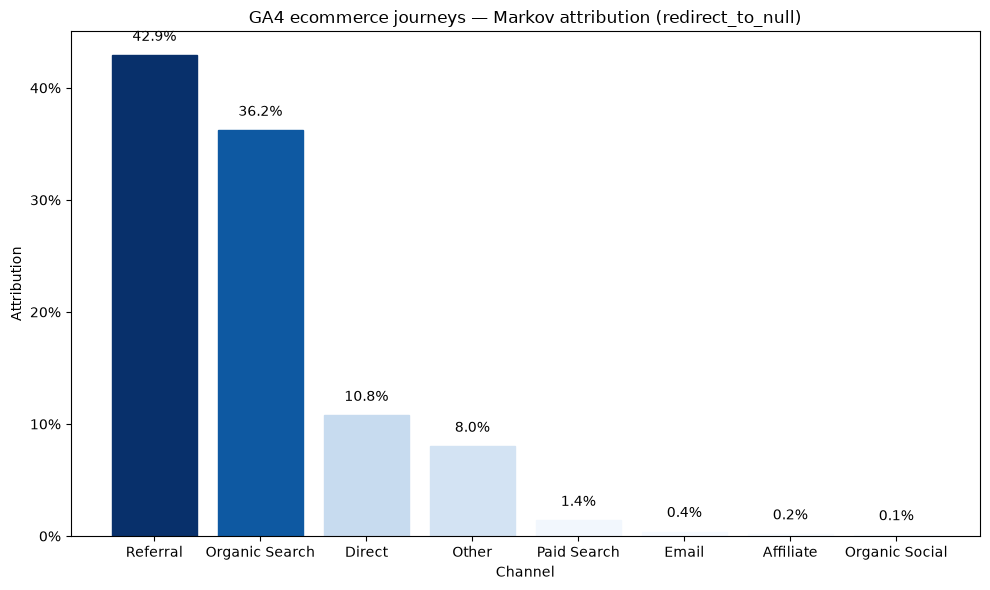

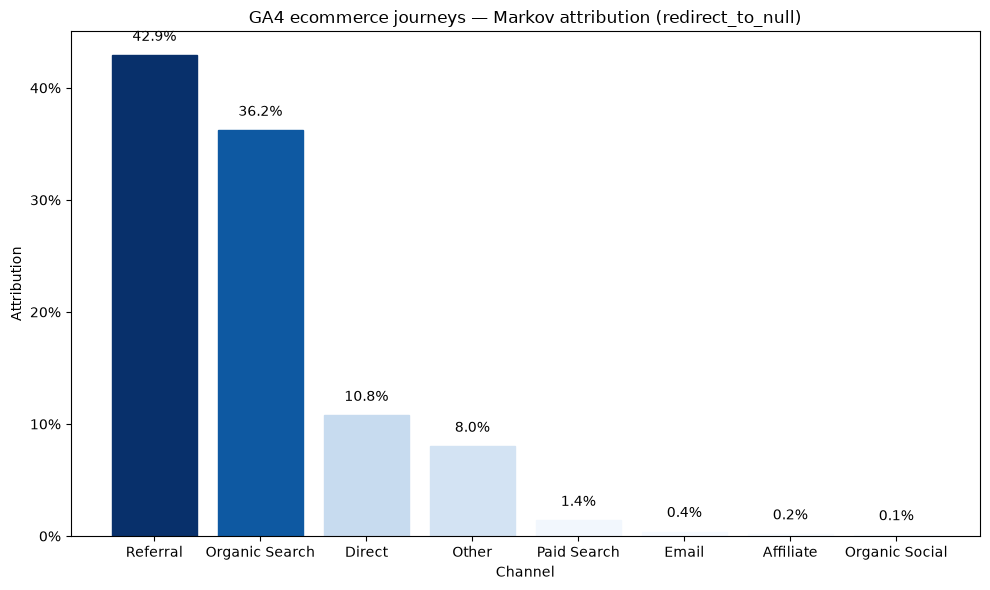

In [7]:
from do_attribution.visualization import plot_attribution

fig = plot_attribution(markov_result["attribution"],
                       title="GA4 ecommerce journeys — Markov attribution (redirect_to_null)")
fig.savefig(IMAGES / "ga4_markov_attribution.png", dpi=110, bbox_inches="tight")
fig

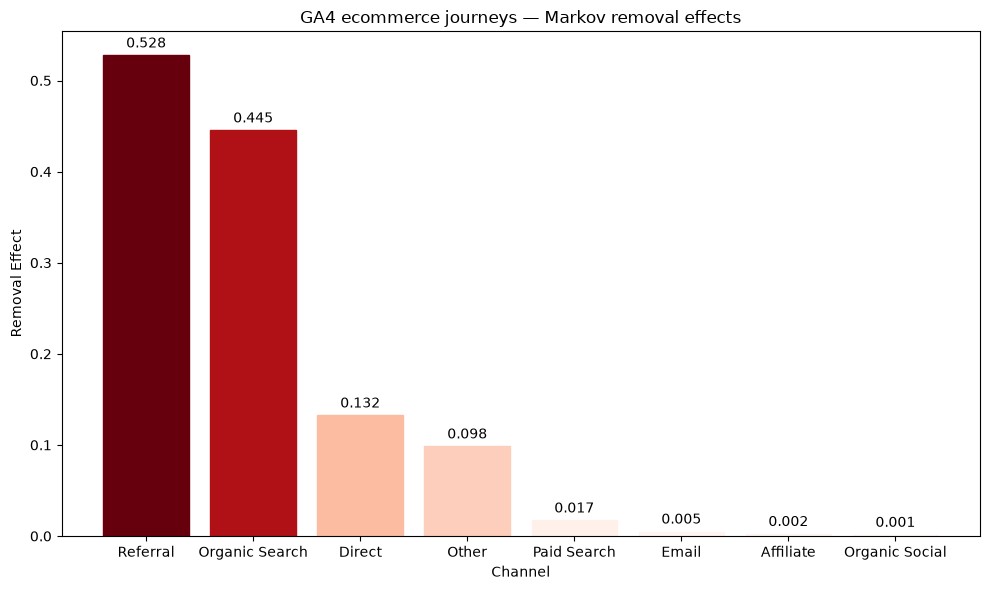

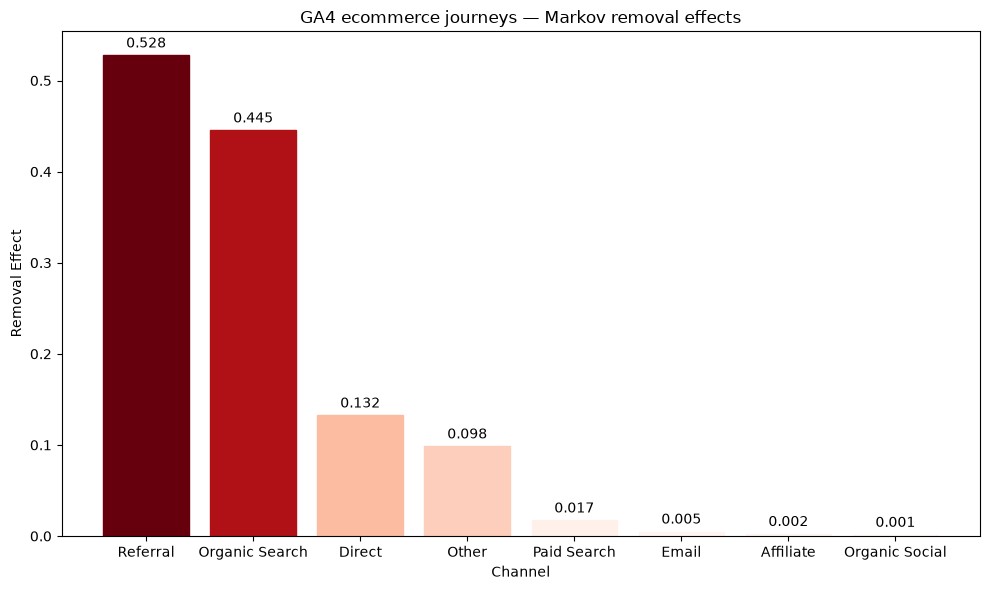

In [8]:
from do_attribution.visualization import plot_removal_effects

fig = plot_removal_effects(markov_result["removal_effects"],
                           title="GA4 ecommerce journeys — Markov removal effects")
fig.savefig(IMAGES / "ga4_markov_removal_effects.png", dpi=110, bbox_inches="tight")
fig

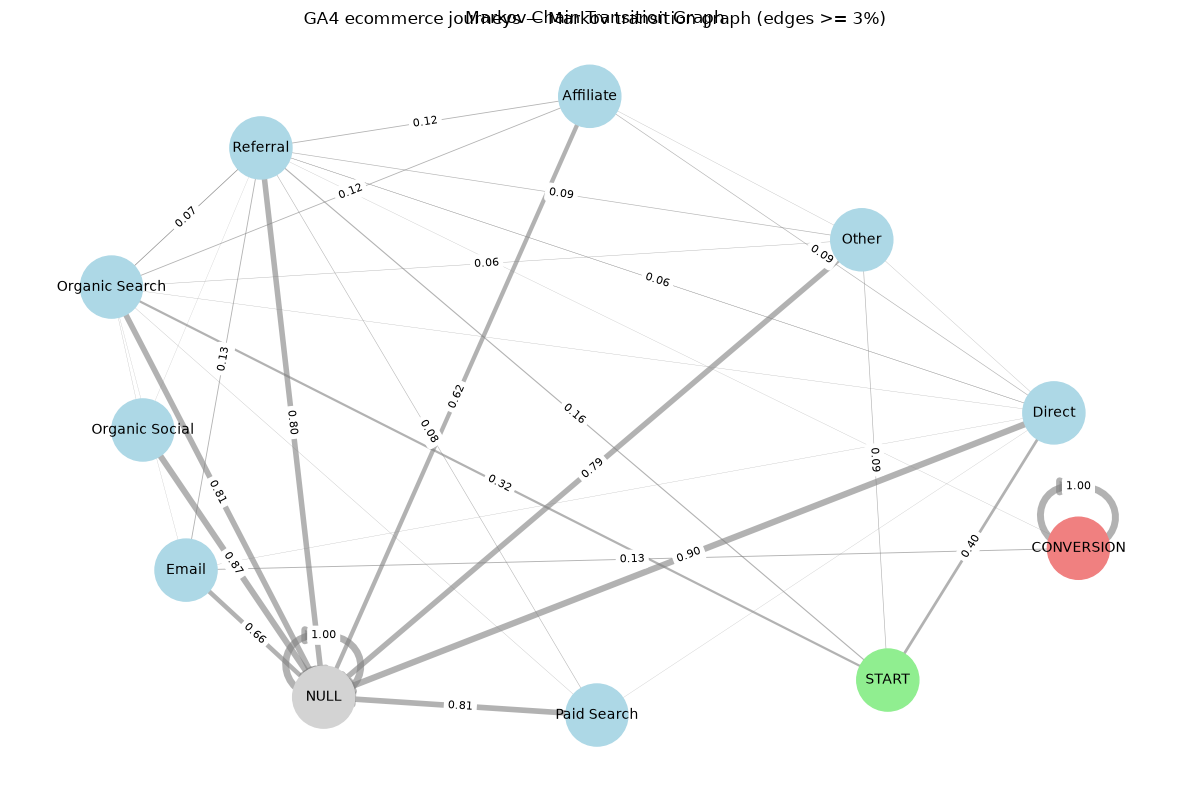

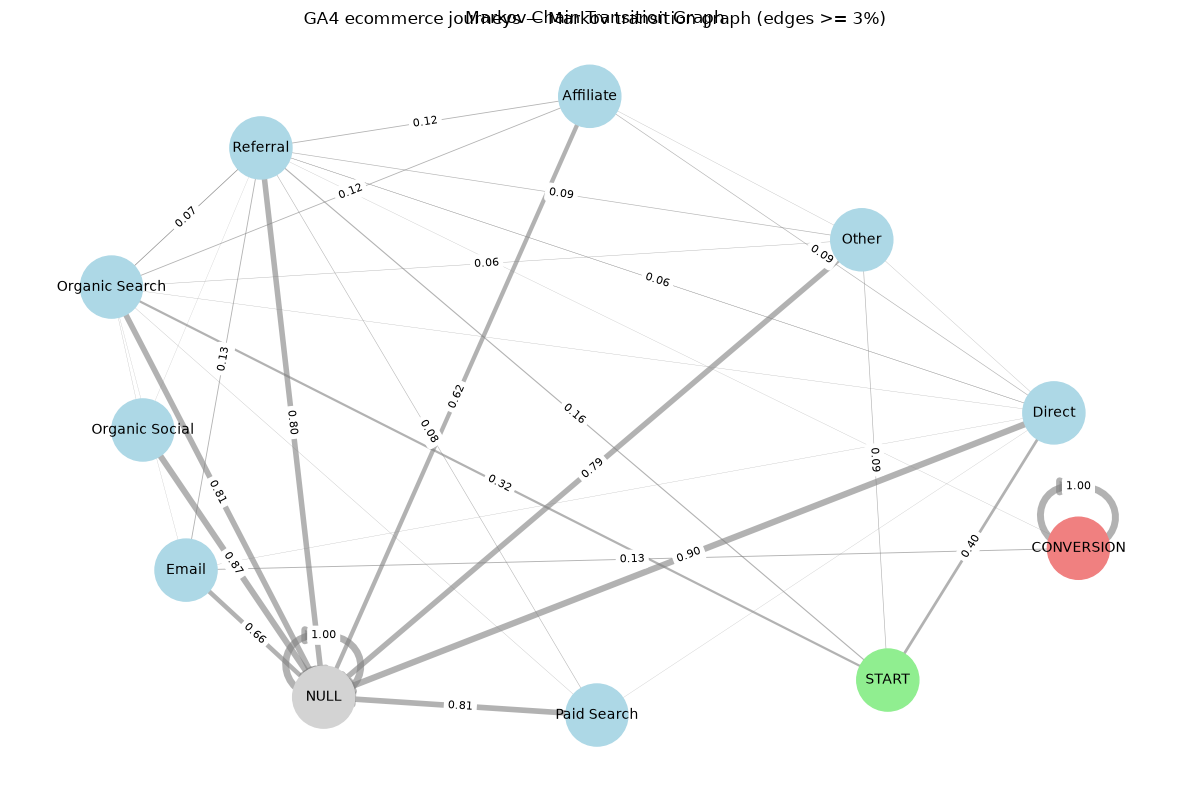

In [9]:
from do_attribution.visualization import plot_transition_graph

fig = plot_transition_graph(transition_matrix, min_edge_weight=0.03)
fig.suptitle("GA4 ecommerce journeys — Markov transition graph (edges >= 3%)", y=0.98)
fig.savefig(IMAGES / "ga4_transition_graph.png", dpi=110, bbox_inches="tight")
fig